# Seminario de Tesis 2 — ML Causal sobre alquileres de departamentos en Lima

## Efecto causal de un baño adicional sobre el precio de alquiler (Double ML)

**Pregunta:** a igualdad de área, dormitorios, antigüedad y ubicación, ¿cuánto sube (en %) el alquiler por un baño más?

Se eligió esta hipótesis (Propuesta 1 del PDF) porque: (i) formaliza la hipótesis 2.8 del `notebook1` ("controlar por área"), (ii) es identificable con los datos disponibles, y (iii) permite mostrar el punto central de las consideraciones del `../prompt.md`: **qué se controla importa tanto como cómo se estima**.

**Estructura**
0. Estado del arte
1. Datos y limpieza (misma lógica del notebook1)
2. Grafos de dependencia (DAG) y clasificación de variables: confusor / mediador / colisionador
3. Línea base: correlación ingenua y OLS hedónico
4. Double ML (LinearDML) paso a paso: residuos "a mano" y con EconML
5. "Todo contra todos" mal hecho: el efecto de los *malos controles*
6. Heterogeneidad (CausalForestDML): CATE por clase de distrito y área
7. Descubrimiento de estructura (PC / LiNGAM) como chequeo del DAG
8. Robustez: refutadores (DoWhy y propios), E-value, robustez de Cinelli-Hazlett
9. Conclusiones y limitaciones

## Estado del arte (resumen)

**Pregunta de la tesis:** ¿cuánto sube causalmente el precio de alquiler de un departamento en Lima por un baño adicional, a igualdad de área, dormitorios, antigüedad y ubicación?

### 1. Precios hedónicos (base teórica)
- Rosen (1974), *Hedonic Prices and Implicit Markets*, JPE: el precio es función de atributos; los coeficientes son precios implícitos.
- En Lima: [Mundaca & Sánchez, *Índice de precios de inmuebles: un enfoque hedónico* (BCRP, Revista Estudios Económicos 36)](https://www.bcrp.gob.pe/docs/Publicaciones/Revista-Estudios-Economicos/36/ree-36-mundaca-sanchez.pdf): las características más valoradas son cocheras y **número de baños**. Es evidencia asociativa, no causal.

### 2. ML predictivo sobre precios de vivienda en Lima (lo más cercano local)
- [Modelo predictivo de precios de alquiler de departamentos en Lima con ML (UPeU)](https://repositorio.upeu.edu.pe/items/ba3c3cfd-b9cf-4d9d-ae1f-4ac6ddc0a646): AutoML/ensembles con área, dormitorios, baños y garajes.
- [Uso de ML para la predicción de precios de departamentos en Lima (ESAN)](https://repositorio.esan.edu.pe/items/ee4f07f0-75a1-4cf5-8427-e9e4bc57a9f0) y comparaciones hedónico vs. XGBoost con datos del BCRP.
- Internacional: [Santiago de Chile, AVM con ML vs. hedónico con ajuste espacial (PLOS ONE)](https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0318701); [Tanzania/Uganda/Malawi, alquileres (PLOS ONE)](https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0244953).
- **Brecha:** estos trabajos *predicen*; ninguno de los encontrados estima el efecto causal de un atributo con identificación explícita (DAG, ignorabilidad condicional, robustez). Esta es la contribución del notebook. (Búsqueda no exhaustiva: conviene completarla en ALICIA/RENATI.)

### 3. ML causal aplicado a vivienda
- [Recovering Direct Price Effects of Environmental Amenities in Housing Markets (arXiv)](https://arxiv.org/pdf/2606.02795): compara hedónico clásico vs. ML causal (causal forest DID) con simulación Monte Carlo empírica.
- [Estimating Causal Effects with Double ML — A Method Evaluation (arXiv)](https://arxiv.org/pdf/2403.14385): evalúa sensibilidad de DML a la elección de learners y supuestos.
- Quasi-experimentos hedónicos: Black (1999, QJE; discontinuidad en fronteras escolares), Chay & Greenstone (2005, JPE), Keele & Titiunik (2015, Political Analysis; fronteras geográficas como RDD) → base de la Propuesta 3 (GeoRDD).

### 4. Metodología causal usada
- Chernozhukov et al. (2018), Double/Debiased ML, *Econometrics Journal*.
- Wager & Athey (2018), Causal Forests, JASA; Athey, Tibshirani & Wager (2019), Generalized Random Forests, *Annals of Statistics*; Nie & Wager (2021), R-learner, Biometrika.
- Pearl (2009), *Causality*; Cinelli, Forney & Pearl (2022), *A Crash Course in Good and Bad Controls*, SMR (confusor / mediador / colisionador).
- Descubrimiento de estructura: Spirtes, Glymour & Scheines (PC); Shimizu et al. (2006, LiNGAM, JMLR); Zheng et al. (2018, NOTEARS, NeurIPS).
- Robustez: Cinelli & Hazlett (2020, JRSSB, robustness value); VanderWeele & Ding (2017, E-value, *Annals of Internal Medicine*); refutadores de DoWhy (Sharma & Kiciman, 2020).

> Nota: las referencias bibliográficas clásicas están citadas de memoria y los enlaces provienen de una búsqueda web; verifica año/volumen antes de incluirlas en la tesis.

## 1. Datos y limpieza

In [1]:
import warnings, sys, types; warnings.filterwarnings("ignore")
# Compatibilidad: 'sparse' (dependencia opcional de econml) requiere numba/llvmlite. Si el sistema no puede cargarlo
# (p.ej. política de control de aplicaciones de Windows), se usa un stub: este análisis solo usa matrices densas.
try:
    import sparse
except Exception as _e:
    print("Aviso: 'sparse' no disponible (%s); se usa stub (no se usan matrices dispersas)." % type(_e).__name__)
    _sp = types.ModuleType("sparse")
    class _COO: pass
    _sp.COO = _sp.SparseArray = _COO
    sys.modules["sparse"] = _sp
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import networkx as nx
from pathlib import Path

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RUTA = Path("../csv/data_wramling_final.csv")
if not RUTA.exists():
    RUTA = Path("../csv/data_wramling_final.csv")
df = pd.read_csv(RUTA).drop(columns=["Unnamed: 0"])
print(df.shape)

(3516, 13)


Limpieza replicada del `notebook1` (outliers de dormitorios/área/precioxm2, combinaciones raras de dormitorios-baños, outliers por distrito).

In [2]:
data = df.copy()
data.drop(index=data.query("dormitorios>6 or area>600 or precioxm2>120 or precioxm2<8").index, inplace=True)
data.drop(index=data.query("dormitorios<=2 and banos==1 and area>=160").index, inplace=True)
data.drop(index=data.query("dormitorios<=2 and banos==2 and area>=250").index, inplace=True)
data.drop(index=data.query("precio<600").index, inplace=True)

# combinaciones (dormitorios, banos) con <=3 casos
cnt = data.groupby(["dormitorios", "banos"]).size()
raras = cnt[cnt <= 3].index
data = data[~data.set_index(["dormitorios", "banos"]).index.isin(raras)]

# outliers de precioxm2 dentro de cada distrito
lim = data.groupby("distrito")["precioxm2"].apply(lambda x: x.quantile(.75) + 2.5*(x.quantile(.75)-x.quantile(.25)))
data = data[data["precioxm2"] <= data["distrito"].map(lim)].copy()
print("Filas tras limpieza:", len(data), "(notebook1/data_hipotesis.csv: 3276)")

Filas tras limpieza: 3276 (notebook1/data_hipotesis.csv: 3276)


### Construcción de variables

- **Y** = `log(precio)` → el coeficiente se lee como *cambio porcentual aproximado*.
- **T** = `banos` (tratamiento, conteo).
- `antiguedad` tiene ~30% de faltantes (`desconocido`). Se imputa con la mediana **y se agrega un indicador de faltante**; así no se descartan filas ni se inventa información sin marcarla.
- `distrito_clase` (clase1/2/3) y `lima_top` replican el notebook1 y se usan solo para analizar heterogeneidad.

In [3]:
clase = {"miraflores":"clase1","san-isidro":"clase1","barranco":"clase1","lince":"clase1",
         "magdalena":"clase2","surquillo":"clase2","jesus-maria":"clase2","san-borja":"clase2","surco":"clase2",
         "cercado":"clase3","san-miguel":"clase3","chorrillos":"clase3","la-molina":"clase3"}
data["distrito_clase"] = data["distrito"].map(clase)
data["lima_top"] = data["distrito"].isin(["miraflores","san-isidro","barranco","lince"]).astype(int)
data["antig_na"] = data["antiguedad"].isna().astype(int)
data["antiguedad_imp"] = data["antiguedad"].fillna(data["antiguedad"].median())
data["area_log"] = np.log(data["area"])
data["Y"] = np.log(data["precio"])
data["T"] = data["banos"].astype(float)
data["tipo_ubic"] = data["type"].where(data["type"].map(data["type"].value_counts()) >= 30, "otro")

# Confusores (PRE-tratamiento): decididos antes/independientemente del nº de baños
NUM = ["area_log", "dormitorios", "antiguedad_imp", "antig_na", "latitud", "longitud", "fecha_publicacion"]
CAT = ["distrito", "tipo_ubic"]
X = pd.concat([data[NUM], pd.get_dummies(data[CAT], drop_first=True).astype(float)], axis=1)
Y, T = data["Y"].values, data["T"].values
print("Confusores:", X.shape[1], "| Y~", Y.mean().round(2), "| T media", T.mean().round(2))
data[["Y","T"]].describe().round(2)

Confusores: 25 | Y~ 7.85 | T media 1.83


,Y,T
count,3276.00,3276.00
mean,7.85,1.83
std,0.55,0.76
min,6.40,1.00
25%,7.55,1.00
50%,7.82,2.00
75%,8.13,2.00
max,9.90,5.00


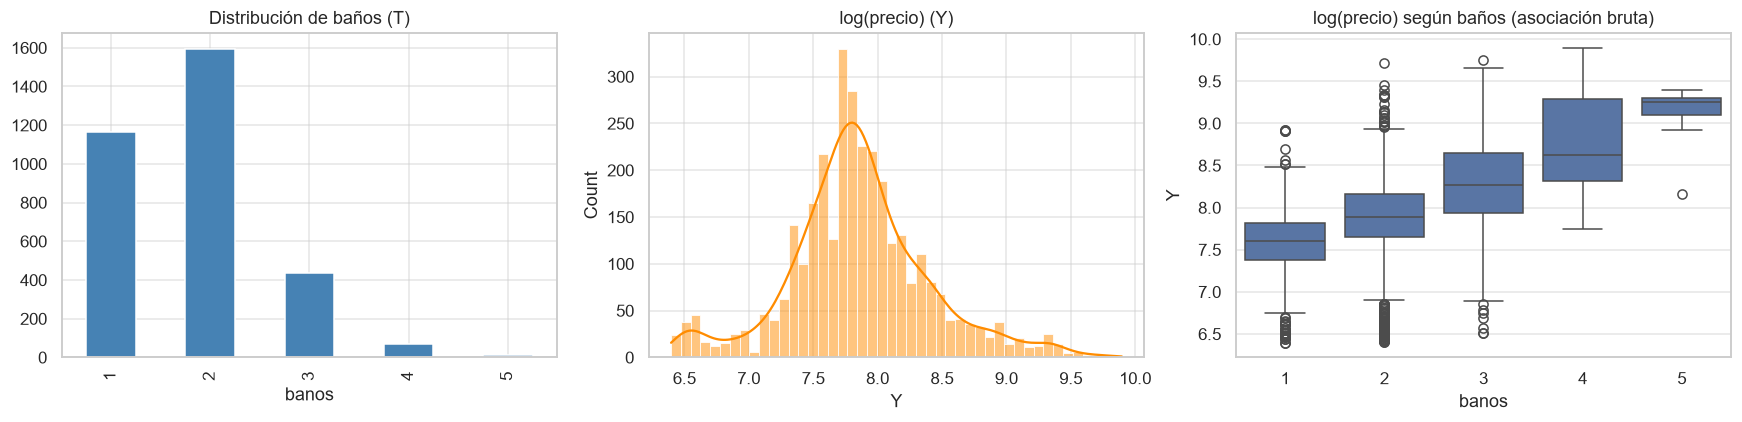

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
data["banos"].value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Distribución de baños (T)")
sns.histplot(data["Y"], kde=True, ax=ax[1], color="darkorange"); ax[1].set_title("log(precio) (Y)")
sns.boxplot(data=data, x="banos", y="Y", ax=ax[2]); ax[2].set_title("log(precio) según baños (asociación bruta)")
plt.tight_layout(); plt.savefig(FIG/"01_distribuciones.png"); plt.show()

## 2. Grafos de dependencia (DAG) — el supuesto causal explícito

Los datos **no dicen** qué variable es confusor, mediador o colisionador; eso lo decide el conocimiento del dominio (orden temporal). Argumento:

| Variable | Rol respecto a T = baños → Y = precio | ¿Controlar? | Justificación |
|---|---|---|---|
| `area` | **Confusor** | Sí | El tamaño existe antes de decidir cuántos baños; causa a T y a Y |
| `distrito`, `latitud/longitud` | **Confusor** | Sí | La ubicación es previa; define el tipo de edificio (más baños) y el precio |
| `antiguedad` | **Confusor** | Sí | Edificios nuevos tienen más baños por diseño y distinto precio |
| `tipo_ubic` (`type`) / `precision` | Proxy de calidad de geocodificación | Sí (`type`) | Correlaciona con zona/tipo de aviso. `precision` se omite (ruido de medición, no causa) |
| `fecha_publicacion` | Previa | Sí | Sin riesgo, absorbe variación temporal |
| `dormitorios` | **Dudosa**: co-determinada con T en el diseño del plano | Sí en la especificación principal; se prueba sin ella | Si es parte del "paquete" de T, controlarla bloquea efecto. Se reportan ambas |
| `precioxm2` | **Colisionador/descendiente de Y** (= precio/área) | **No** | Función del resultado: controlarla distorsiona |
| `precio`, `precio_log` | Es Y | — | — |
| `banos/dormitorio` | Función de T | **No** | Contiene T |
| `lima_top`, `distrito_clase` | Función de `distrito` | No hace falta | Redundantes; se usan para heterogeneidad |
| acabados, piso, vista, seguridad | **Confusores no observados (U)** | No disponibles | Principal amenaza → sección 8 |

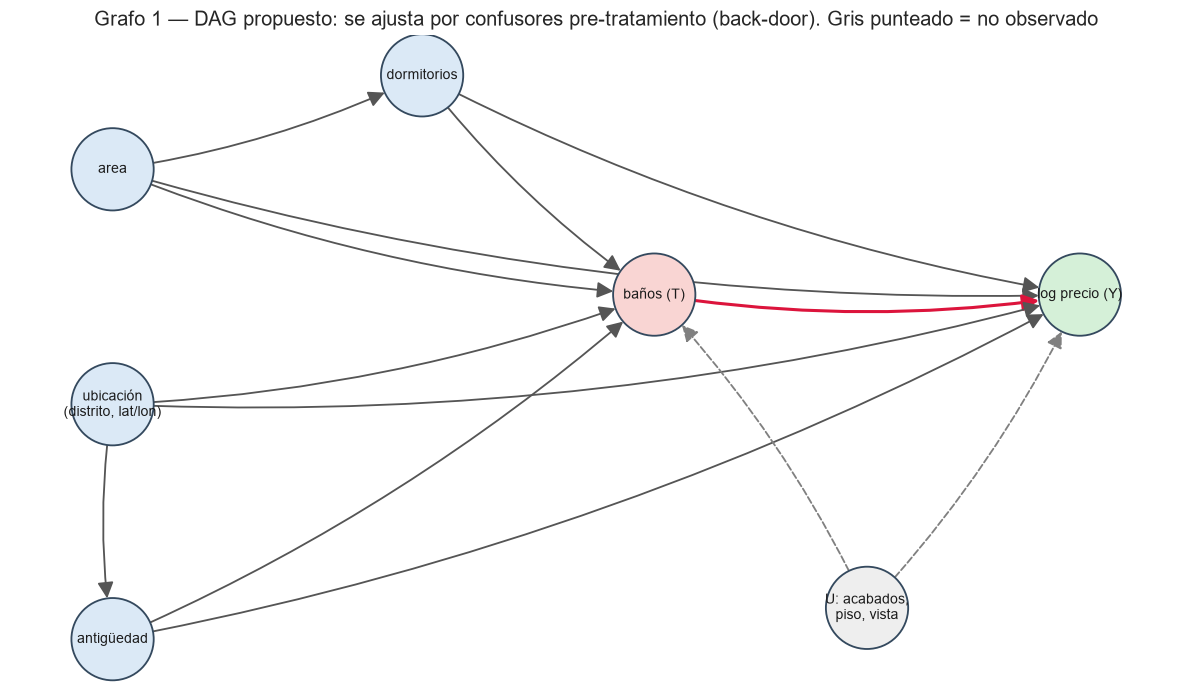

In [5]:
def dibujar(G, pos, titulo, archivo, colores=None, estilos=None, figsize=(11, 6.5)):
    fig, ax = plt.subplots(figsize=figsize)
    colores = colores or {}
    nx.draw_networkx_nodes(G, pos, node_size=2900, ax=ax,
                           node_color=[colores.get(n, "#dbe9f6") for n in G.nodes],
                           edgecolors="#34495e", linewidths=1.2)
    nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
    for u, v, d in G.edges(data=True):
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax, arrows=True, arrowsize=22,
                               node_size=2900, width=2 if d.get("principal") else 1.2,
                               edge_color=d.get("color", "#555"), style=d.get("style", "solid"),
                               connectionstyle="arc3,rad=0.08")
    ax.set_title(titulo, fontsize=13); ax.axis("off"); plt.tight_layout()
    plt.savefig(FIG/archivo, bbox_inches="tight"); plt.show()

# --- Grafo 1: DAG causal propuesto (identificación back-door) ---
G1 = nx.DiGraph()
for c in ["area", "ubicación\n(distrito, lat/lon)", "antigüedad"]:
    G1.add_edge(c, "baños (T)"); G1.add_edge(c, "log precio (Y)")
G1.add_edge("area", "dormitorios"); G1.add_edge("dormitorios", "baños (T)"); G1.add_edge("dormitorios", "log precio (Y)")
G1.add_edge("ubicación\n(distrito, lat/lon)", "antigüedad")
G1.add_edge("baños (T)", "log precio (Y)", color="crimson", principal=True)
G1.add_edge("U: acabados,\npiso, vista", "baños (T)", color="gray", style="dashed")
G1.add_edge("U: acabados,\npiso, vista", "log precio (Y)", color="gray", style="dashed")
pos1 = {"area": (0, 2), "ubicación\n(distrito, lat/lon)": (0, 0.5), "antigüedad": (0, -1), "dormitorios": (1.6, 2.6),
        "baños (T)": (2.8, 1.2), "log precio (Y)": (5, 1.2), "U: acabados,\npiso, vista": (3.9, -0.8)}
col1 = {"baños (T)": "#f9d5d3", "log precio (Y)": "#d5f0d8", "U: acabados,\npiso, vista": "#eeeeee"}
dibujar(G1, pos1, "Grafo 1 — DAG propuesto: se ajusta por confusores pre-tratamiento (back-door). Gris punteado = no observado", "02_dag_propuesto.png", col1)

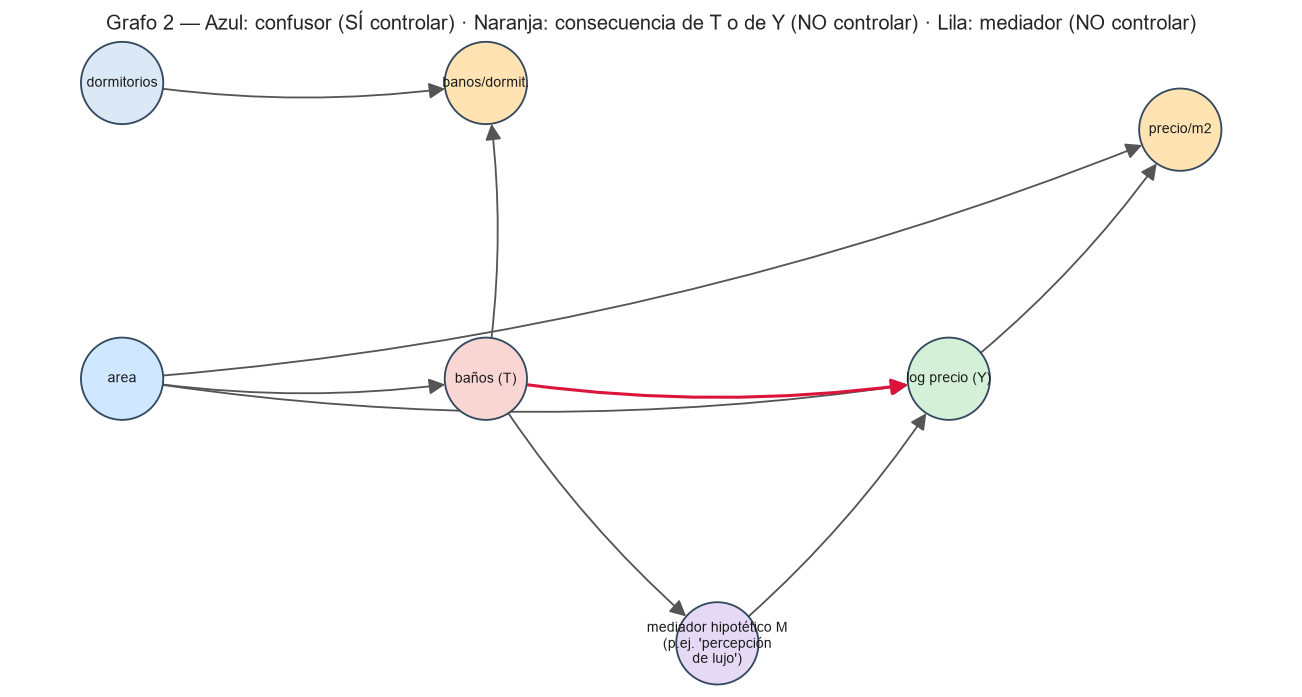

In [6]:
# --- Grafo 2: tipos de variables (confusor / mediador / colisionador) ---
G2 = nx.DiGraph()
G2.add_edge("area", "baños (T)"); G2.add_edge("area", "log precio (Y)")                 # confusor
G2.add_edge("baños (T)", "log precio (Y)", color="crimson", principal=True)
G2.add_edge("baños (T)", "banos/dormit."); G2.add_edge("dormitorios", "banos/dormit.")  # función de T
G2.add_edge("log precio (Y)", "precio/m2"); G2.add_edge("area", "precio/m2")           # descendiente de Y (colisionador)
G2.add_edge("baños (T)", "mediador hipotético M\n(p.ej. 'percepción\nde lujo')"); G2.add_edge("mediador hipotético M\n(p.ej. 'percepción\nde lujo')", "log precio (Y)")
pos2 = {"area": (0, 1.4), "baños (T)": (2.2, 1.4), "log precio (Y)": (5.0, 1.4), "banos/dormit.": (2.2, 3.3), "dormitorios": (0, 3.3),
        "precio/m2": (6.4, 3.0), "mediador hipotético M\n(p.ej. 'percepción\nde lujo')": (3.6, -0.3)}
col2 = {"area": "#cfe8ff", "baños (T)": "#f9d5d3", "log precio (Y)": "#d5f0d8", "banos/dormit.": "#ffe3b3", "precio/m2": "#ffe3b3",
        "mediador hipotético M\n(p.ej. 'percepción\nde lujo')": "#e6d9f5"}
dibujar(G2, pos2, "Grafo 2 — Azul: confusor (SÍ controlar) · Naranja: consecuencia de T o de Y (NO controlar) · Lila: mediador (NO controlar)", "03_dag_tipos_variables.png", col2, figsize=(12, 6.5))

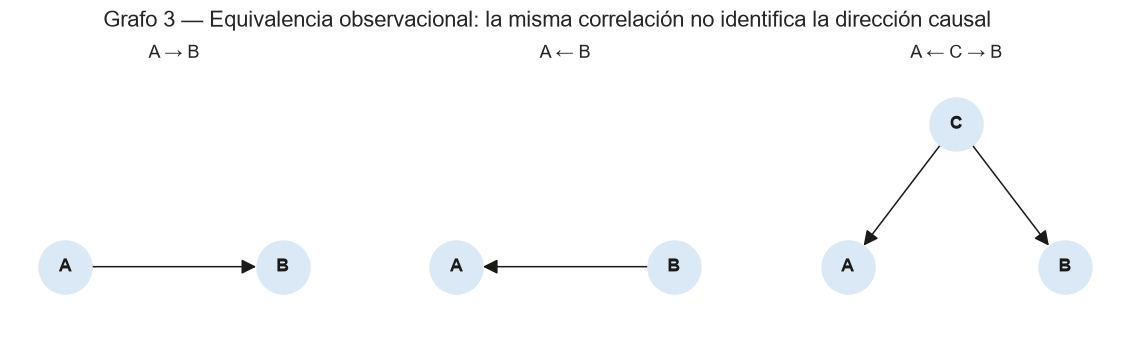

In [7]:
# --- Grafo 3: las 3 historias que producen la MISMA correlación ---
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
casos = [("A → B", [("A","B")]), ("A ← B", [("B","A")]), ("A ← C → B", [("C","A"),("C","B")])]
pp = [{"A":(0,0),"B":(2,0)}, {"A":(0,0),"B":(2,0)}, {"A":(0,0),"B":(2,0),"C":(1,1)}]
for a, (t, e), p in zip(axs, casos, pp):
    g = nx.DiGraph(e); nx.draw(g, p, ax=a, with_labels=True, node_size=1200, node_color="#dbe9f6", arrowsize=20, font_weight="bold")
    a.set_title(t); a.set_xlim(-.5, 2.5); a.set_ylim(-.5, 1.4)
fig.suptitle("Grafo 3 — Equivalencia observacional: la misma correlación no identifica la dirección causal", y=1.04)
plt.savefig(FIG/"04_equivalencia_observacional.png", bbox_inches="tight"); plt.show()

## 3. Línea base: correlación ingenua y OLS hedónico

La diferencia entre la asociación bruta y el efecto ajustado es el síntoma de confusión que describe el PDF.

In [8]:
import statsmodels.api as sm

def ols_efecto(cols_extra, nombre):
    Xo = sm.add_constant(pd.concat([data[["T"]], cols_extra], axis=1))
    r = sm.OLS(data["Y"], Xo).fit(cov_type="HC3")
    b, se = r.params["T"], r.bse["T"]
    return {"modelo": nombre, "efecto (log)": b, "% aprox": 100*(np.exp(b)-1), "IC95 inf": b-1.96*se, "IC95 sup": b+1.96*se}

filas = [
    ols_efecto(pd.DataFrame(index=data.index), "OLS ingenuo (sin controles)"),
    ols_efecto(data[["area_log"]], "OLS + área"),
    ols_efecto(X, "OLS hedónico (todos los confusores, lineal)"),
]
base = pd.DataFrame(filas).set_index("modelo").round(4)
base

,efecto (log),% aprox,IC95 inf,IC95 sup
modelo,,,,
OLS ingenuo (sin controles),0.3676,44.4216,0.3461,0.3890
OLS + área,0.0445,4.5489,0.0192,0.0698
"OLS hedónico (todos los confusores, lineal)",0.0851,8.8780,0.0606,0.1095


Sin controles, el baño parece 'valer' mucho más porque los baños proxy del tamaño y la zona. El ajuste lineal ya reduce el efecto sustancialmente.

## 4. Double ML paso a paso

**Idea (Frisch-Waugh-Lovell con ML):**
1. Ajustar `E[Y|X]` con ML flexible → residuo `Ỹ = Y − Ê[Y|X]` (precio no explicado por los controles)
2. Ajustar `E[T|X]` con ML flexible → residuo `T̃ = T − Ê[T|X]` (baños no explicados por los controles)
3. Regresar `Ỹ` sobre `T̃`: el coeficiente es el efecto causal **bajo el supuesto** de que `T̃` es "como aleatorio".

Las predicciones se hacen con **cross-fitting** (cada fila se predice con modelos entrenados en otros folds) para evitar sobreajuste.

In [9]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import GradientBoostingRegressor as GBR

def gbr(): return GBR(n_estimators=250, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)

def dml_manual(Y, T, X):
    y_hat = cross_val_predict(gbr(), X, Y, cv=kf)
    t_hat = cross_val_predict(gbr(), X, T, cv=kf)
    ry, rt = Y - y_hat, T - t_hat
    theta = (rt @ ry) / (rt @ rt)
    # error estándar robusto (score ortogonal)
    psi = (ry - theta*rt) * rt
    se = np.sqrt(np.mean(psi**2) / len(Y)) / np.mean(rt**2)
    return theta, se, ry, rt, y_hat, t_hat

theta, se, ry, rt, y_hat, t_hat = dml_manual(Y, T, X)
print(f"DML manual: theta = {theta:.4f}  (SE {se:.4f})  IC95 [{theta-1.96*se:.4f}, {theta+1.96*se:.4f}]  ≈ {100*(np.exp(theta)-1):.1f}% por baño")
print(f"R² del nuisance de Y: {1-np.var(ry)/np.var(Y):.3f} | R² del nuisance de T: {1-np.var(rt)/np.var(T):.3f}")

DML manual: theta = 0.0528  (SE 0.0121)  IC95 [0.0290, 0.0766]  ≈ 5.4% por baño
R² del nuisance de Y: 0.654 | R² del nuisance de T: 0.631


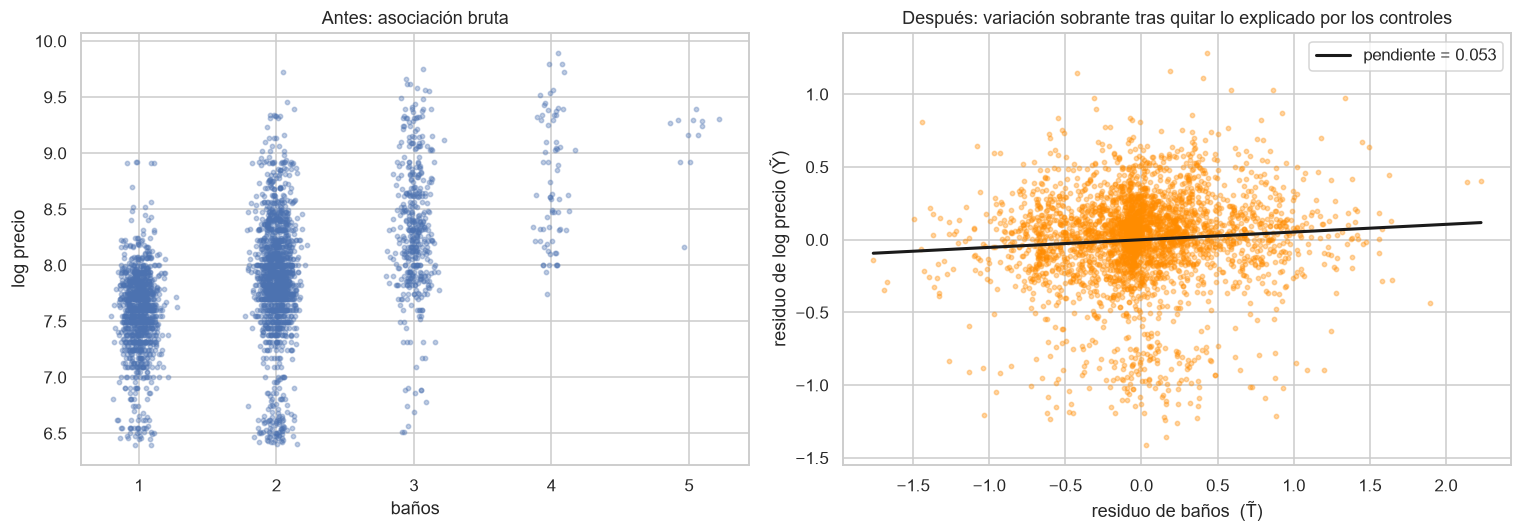

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(T + np.random.normal(0, .07, len(T)), Y, s=8, alpha=.35); ax[0].set_xlabel("baños"); ax[0].set_ylabel("log precio"); ax[0].set_title("Antes: asociación bruta")
ax[1].scatter(rt, ry, s=8, alpha=.35, color="darkorange")
xs = np.linspace(rt.min(), rt.max(), 50); ax[1].plot(xs, theta*xs, "k", lw=2, label=f"pendiente = {theta:.3f}")
ax[1].set_xlabel("residuo de baños  (T̃)"); ax[1].set_ylabel("residuo de log precio (Ỹ)"); ax[1].legend()
ax[1].set_title("Después: variación sobrante tras quitar lo explicado por los controles")
plt.tight_layout(); plt.savefig(FIG/"05_residuos_dml.png"); plt.show()

Ahora con **EconML** (`LinearDML`), que añade inferencia y es la herramienta que sugiere el PDF. Se verifica que coincida con el cálculo manual.

In [11]:
from econml.dml import LinearDML, CausalForestDML

est = LinearDML(model_y=gbr(), model_t=gbr(), discrete_treatment=False, cv=5, random_state=SEED)
est.fit(Y, T, X=None, W=X)          # efecto constante; X en W como controles
ate = est.const_marginal_ate()
lo, hi = est.const_marginal_ate_interval(alpha=0.05)
print(f"LinearDML (EconML): ATE = {float(np.ravel(ate)[0]):.4f}  IC95 [{float(np.ravel(lo)[0]):.4f}, {float(np.ravel(hi)[0]):.4f}]  ≈ {100*(np.exp(float(np.ravel(ate)[0]))-1):.1f}% por baño")
ate_dml = float(np.ravel(ate)[0]); ci_dml = (float(np.ravel(lo)[0]), float(np.ravel(hi)[0]))

LinearDML (EconML): ATE = 0.0528  IC95 [0.0290, 0.0766]  ≈ 5.4% por baño


## 5. "Todo contra todos" mal hecho: el efecto de los malos controles

Se estima el mismo efecto cambiando el conjunto de controles. Solo debe cambiar lo que **debe** cambiar:

- **Sin dormitorios**: el efecto total del "paquete" (baños arrastran dormitorios).
- **+ `precioxm2` (colisionador/descendiente de Y)**: control prohibido → sesgo.
- **+ `banos/dormitorio` (función de T)**: control prohibido.
- **Sin ubicación / sin área**: sesgo por confusor omitido.

In [12]:
data["banos_dorm"] = data["banos"]/data["dormitorios"]

def dml_spec(cols, nombre):
    Xs = pd.concat([data[[c for c in cols if c in data.columns]],
                    pd.get_dummies(data[[c for c in cols if c in CAT]], drop_first=True).astype(float)], axis=1)
    Xs = Xs.drop(columns=[c for c in CAT if c in Xs.columns])
    th, s, *_ = dml_manual(Y, T, Xs)
    return {"especificación": nombre, "theta": th, "IC inf": th-1.96*s, "IC sup": th+1.96*s, "% aprox": 100*(np.exp(th)-1)}

base_cols = NUM + CAT
specs = {
 "✔ Principal (confusores pre-tratamiento)": base_cols,
 "~ Sin dormitorios (efecto 'paquete')": [c for c in base_cols if c != "dormitorios"],
 "✘ Sin ubicación (confusor omitido)": [c for c in base_cols if c not in ("distrito","latitud","longitud")],
 "✘ Sin área (confusor omitido)": [c for c in base_cols if c != "area_log"],
 "✘ + precioxm2 (colisionador)": base_cols + ["precioxm2"],
 "✘ + baños/dormitorio (contiene T)": base_cols + ["banos_dorm"],
}
res_specs = pd.DataFrame([dml_spec(c, n) for n, c in specs.items()]).set_index("especificación").round(4)
res_specs

,theta,IC inf,IC sup,% aprox
especificación,,,,
✔ Principal (confusores pre-tratamiento),0.0528,0.0290,0.0766,5.4207
~ Sin dormitorios (efecto 'paquete'),0.0509,0.0286,0.0732,5.2240
✘ Sin ubicación (confusor omitido),0.0713,0.0445,0.0981,7.3906
✘ Sin área (confusor omitido),0.1951,0.1685,0.2218,21.5470
✘ + precioxm2 (colisionador),-0.0003,-0.0030,0.0025,-0.0251
✘ + baños/dormitorio (contiene T),0.3593,-0.5313,1.2499,43.2298


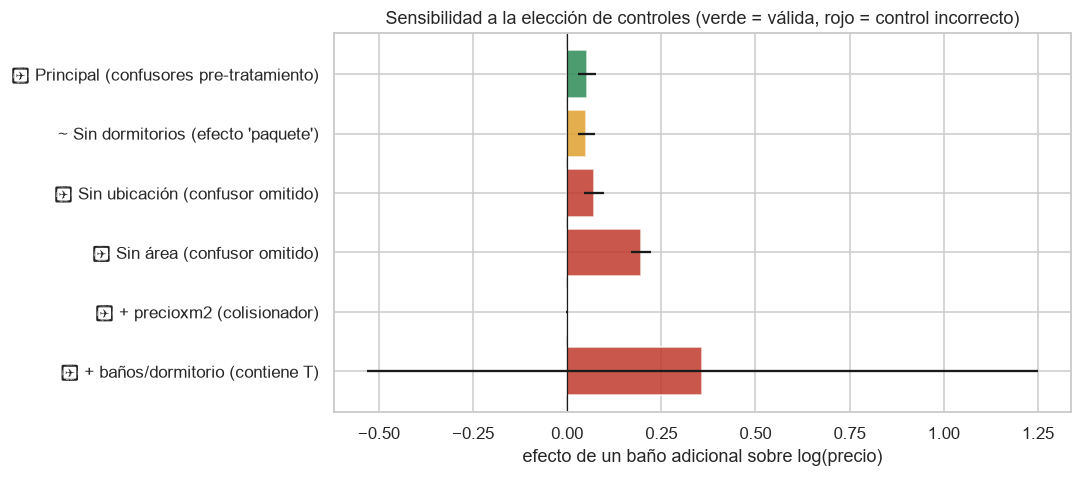

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
r = res_specs.reset_index()
cols = ["#2e8b57" if s.startswith("✔") else ("#e0a030" if s.startswith("~") else "#c0392b") for s in r["especificación"]]
ax.barh(r["especificación"], r["theta"], xerr=[r["theta"]-r["IC inf"], r["IC sup"]-r["theta"]], color=cols, alpha=.85)
ax.axvline(0, color="k", lw=.8); ax.invert_yaxis(); ax.set_xlabel("efecto de un baño adicional sobre log(precio)")
ax.set_title("Sensibilidad a la elección de controles (verde = válida, rojo = control incorrecto)")
plt.tight_layout(); plt.savefig(FIG/"06_malos_controles.png"); plt.show()

**Lectura:** al incluir `precioxm2` (= precio/área) el efecto colapsa a ≈ 0, porque se controla por una función del resultado; con `baños/dormitorio` (contiene T) la estimación se vuelve inestable (IC enorme). Omitir el **área** infla el efecto (~21%) y omitir la ubicación lo infla levemente. Más variables ≠ mejor: la validez viene del DAG, no del ajuste.

## 6. Heterogeneidad: CATE con Causal Forest DML

¿El valor de un baño extra es distinto en distritos caros vs. baratos, o en departamentos chicos vs. grandes? `CausalForestDML` estima un efecto por propiedad `θ(x)`; heterogeneidad se modela con (`area_log`, `antiguedad_imp`, `lima_top`, `dormitorios`); el resto de controles va en `W`.

In [14]:
het = ["area_log", "dormitorios", "antiguedad_imp", "lima_top"]
Xh = data[het].values
W = X.drop(columns=[c for c in het if c in X.columns]).values

cf = CausalForestDML(model_y=gbr(), model_t=gbr(), n_estimators=400, min_samples_leaf=15,
                     discrete_treatment=False, cv=5, random_state=SEED)
cf.fit(Y, T, X=Xh, W=W)
data["cate"] = cf.effect(Xh)
lo_i, hi_i = cf.effect_interval(Xh, alpha=0.05)
data["cate_lo"], data["cate_hi"] = lo_i, hi_i
print("ATE (forest):", round(float(cf.ate(Xh)), 4), " IC95:", np.round(cf.ate_interval(Xh, alpha=0.05), 4))
tab = data.groupby("distrito_clase")["cate"].agg(["mean", "std", "count"]).round(4)
tab["% aprox"] = (100*(np.exp(tab["mean"])-1)).round(1)
tab

ATE (forest): 0.0583  IC95: [-0.0357  0.1524]


,mean,std,count,% aprox
distrito_clase,,,,
clase1,0.0533,0.0335,1259,5.5
clase2,0.0624,0.0470,1121,6.4
clase3,0.0604,0.0474,896,6.2


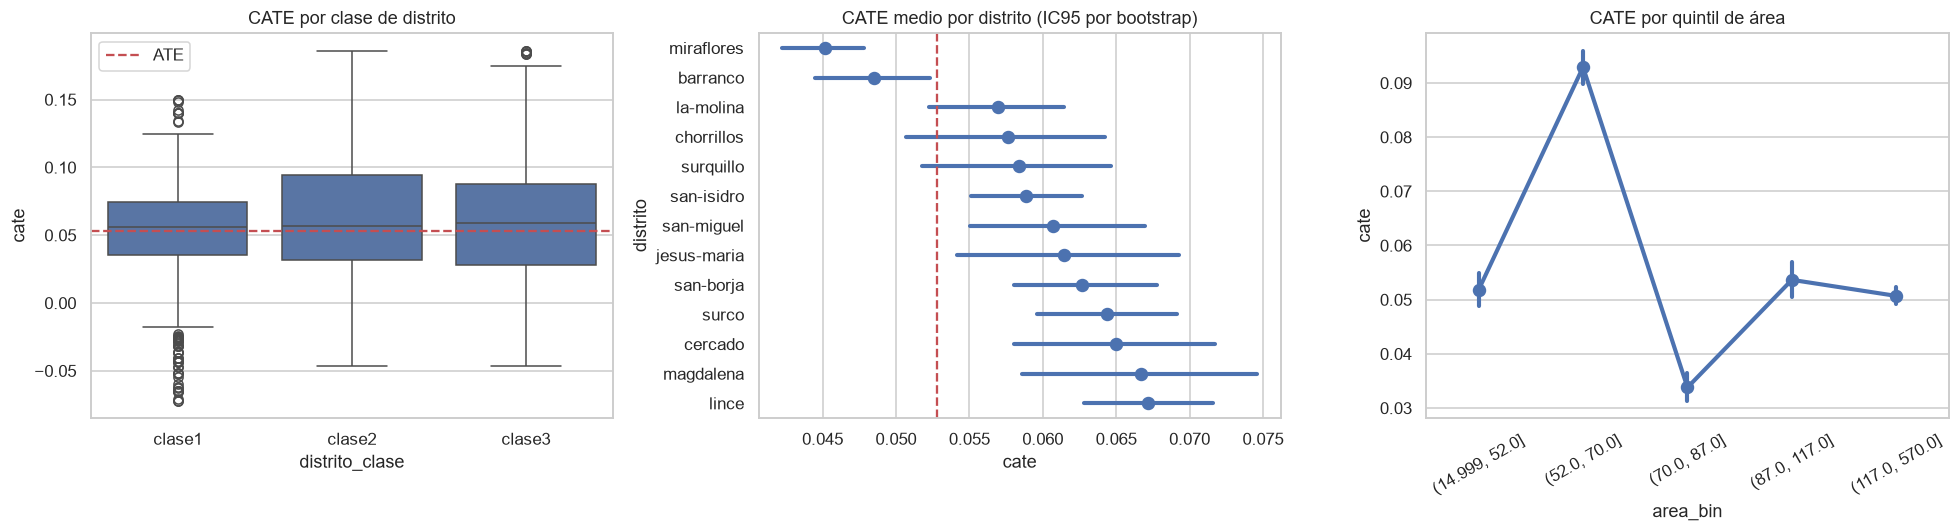

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=data, x="distrito_clase", y="cate", ax=ax[0], order=["clase1","clase2","clase3"]); ax[0].axhline(ate_dml, color="r", ls="--", label="ATE"); ax[0].legend(); ax[0].set_title("CATE por clase de distrito")
orden = data.groupby("distrito")["cate"].mean().sort_values().index
sns.pointplot(data=data, x="cate", y="distrito", order=orden, errorbar=("ci", 95), ax=ax[1], linestyle="none"); ax[1].axvline(ate_dml, color="r", ls="--"); ax[1].set_title("CATE medio por distrito (IC95 por bootstrap)")
data["area_bin"] = pd.qcut(data["area"], 5)
sns.pointplot(data=data, x="area_bin", y="cate", errorbar=("ci", 95), ax=ax[2]); ax[2].tick_params(axis="x", rotation=30); ax[2].set_title("CATE por quintil de área")
plt.tight_layout(); plt.savefig(FIG/"07_cate.png"); plt.show()

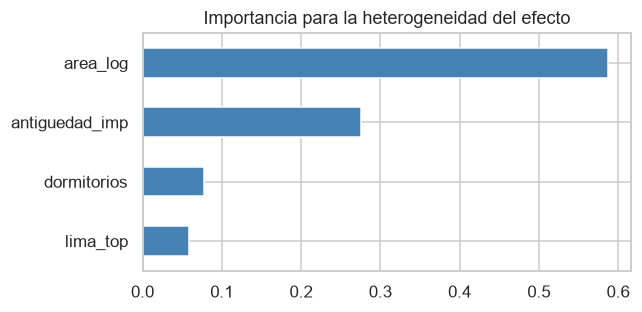

In [16]:
# ¿Qué variables explican la heterogeneidad? (importancia del forest)
imp = pd.Series(cf.feature_importances_, index=het).sort_values()
imp.plot.barh(color="steelblue", figsize=(6, 3)); plt.title("Importancia para la heterogeneidad del efecto"); plt.tight_layout()
plt.savefig(FIG/"08_importancia_heterogeneidad.png"); plt.show()

## 7. Descubrimiento de estructura (PC y LiNGAM) como *chequeo* del DAG

Los algoritmos "todo contra todos" aprenden un grafo desde los datos, pero asumen **sin confusores ocultos** y a menudo **no orientan** flechas. Se usan para contrastar el DAG propuesto, con conocimiento previo del orden temporal (nada puede causar `latitud/longitud`, `area` ni `antiguedad`; `Y` no causa a nada).

In [17]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge
from causallearn.graph.GraphNode import GraphNode

vars_cd = ["area_log", "dormitorios", "antiguedad_imp", "latitud", "longitud", "T", "Y"]
nombres = {"area_log":"área","dormitorios":"dormit.","antiguedad_imp":"antigüedad","latitud":"lat","longitud":"lon","T":"baños (T)","Y":"log precio (Y)"}
Z = (data[vars_cd] - data[vars_cd].mean()) / data[vars_cd].std()
nodes = [GraphNode(f"X{i+1}") for i in range(len(vars_cd))]
bk = BackgroundKnowledge()
exog = [0, 2, 3, 4]                       # área, antigüedad, lat, lon: exógenas
for i in range(len(vars_cd)):
    for j in exog:
        if i != j: bk.add_forbidden_by_node(nodes[i], nodes[j])
for j in range(len(vars_cd)-1):           # Y (último) no causa a nada
    bk.add_forbidden_by_node(nodes[-1], nodes[j])

cg = pc(Z.values, alpha=0.01, indep_test="fisherz", background_knowledge=bk, show_progress=False)
A = cg.G.graph
Gpc = nx.DiGraph(); Gpc.add_nodes_from(nombres.values())
und = []
for i in range(len(vars_cd)):
    for j in range(len(vars_cd)):
        if A[j, i] == 1 and A[i, j] == -1: Gpc.add_edge(nombres[vars_cd[i]], nombres[vars_cd[j]])  # i -> j
        elif A[i, j] == -1 and A[j, i] == -1 and i < j: und.append((nombres[vars_cd[i]], nombres[vars_cd[j]]))
print("Aristas dirigidas:", list(Gpc.edges)); print("Aristas sin orientar:", und)

Aristas dirigidas: [('área', 'dormit.'), ('área', 'baños (T)'), ('área', 'log precio (Y)'), ('lat', 'log precio (Y)'), ('baños (T)', 'log precio (Y)')]
Aristas sin orientar: [('dormit.', 'baños (T)')]


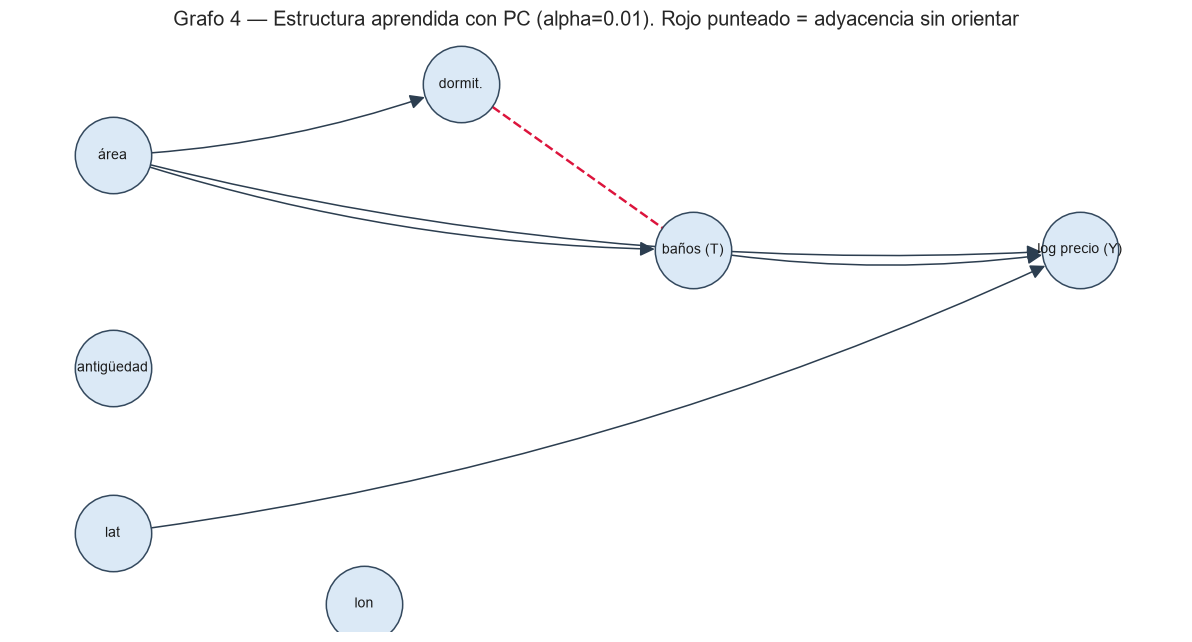

In [18]:
pos7 = {"área": (0, 2), "antigüedad": (0, 0.2), "lat": (0, -1.2), "lon": (1.3, -1.8), "dormit.": (1.8, 2.6), "baños (T)": (3, 1.2), "log precio (Y)": (5, 1.2)}
fig, ax = plt.subplots(figsize=(11, 6))
nx.draw_networkx_nodes(Gpc, pos7, node_size=2500, node_color="#dbe9f6", edgecolors="#34495e", ax=ax)
nx.draw_networkx_labels(Gpc, pos7, font_size=9, ax=ax)
nx.draw_networkx_edges(Gpc, pos7, arrows=True, arrowsize=20, node_size=2500, edge_color="#2c3e50", ax=ax, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edges(nx.Graph(und), pos7, style="dashed", edge_color="crimson", width=1.6, ax=ax)
ax.set_title("Grafo 4 — Estructura aprendida con PC (alpha=0.01). Rojo punteado = adyacencia sin orientar", fontsize=13); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG/"09_grafo_pc.png", bbox_inches="tight"); plt.show()

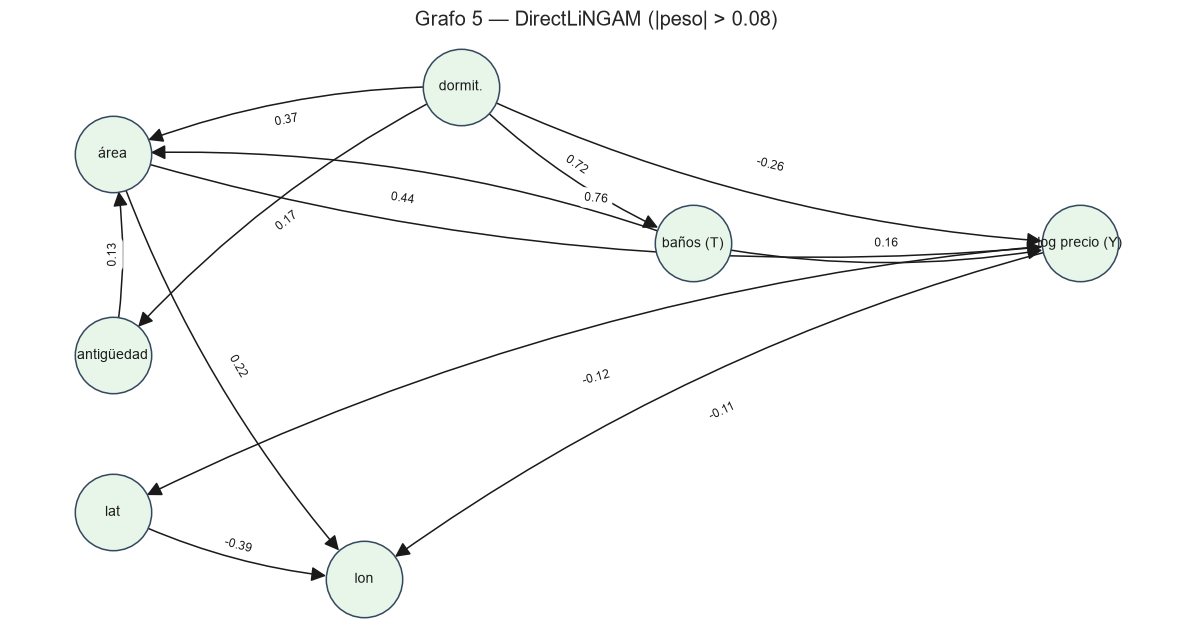

Peso baños → log precio (LiNGAM): 0.156


In [19]:
# LiNGAM (asume no-gaussianidad; chequeo complementario)
try:
    from causallearn.search.FCMBased import lingam
    m = lingam.DirectLiNGAM(); m.fit(Z.values)
    B = m.adjacency_matrix_            # B[i, j] = efecto de j sobre i
    GL = nx.DiGraph(); GL.add_nodes_from(nombres.values())
    for i in range(len(vars_cd)):
        for j in range(len(vars_cd)):
            if abs(B[i, j]) > 0.08: GL.add_edge(nombres[vars_cd[j]], nombres[vars_cd[i]], w=round(B[i, j], 2))
    fig, ax = plt.subplots(figsize=(11, 6))
    nx.draw_networkx_nodes(GL, pos7, node_size=2500, node_color="#e8f5e9", edgecolors="#34495e", ax=ax)
    nx.draw_networkx_labels(GL, pos7, font_size=9, ax=ax)
    nx.draw_networkx_edges(GL, pos7, arrows=True, arrowsize=20, node_size=2500, ax=ax, connectionstyle="arc3,rad=0.1")
    nx.draw_networkx_edge_labels(GL, pos7, edge_labels=nx.get_edge_attributes(GL, "w"), font_size=8, ax=ax)
    ax.set_title("Grafo 5 — DirectLiNGAM (|peso| > 0.08)", fontsize=13); ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG/"10_grafo_lingam.png", bbox_inches="tight"); plt.show()
    print("Peso baños → log precio (LiNGAM):", round(B[vars_cd.index('Y'), vars_cd.index('T')], 3))
except Exception as e:
    print("LiNGAM no disponible:", e)

**Lectura:** si PC/LiNGAM recuperan `área → baños → precio` y `área → precio`, respaldan el DAG propuesto (consistencia, no prueba). Las adyacencias sin orientar muestran el límite de estos algoritmos.

## 8. Robustez: ¿cuán frágil es el resultado?

### 8.1 Identificación y refutadores con DoWhy
DoWhy formaliza el modelo (DAG → estimando) y aplica refutadores. Se usa el estimador lineal ajustado por el conjunto back-door.

In [20]:
import networkx as nx
# Compatibilidad dowhy 0.8 + networkx>=3.4 (d_separated fue renombrada a is_d_separator)
if not hasattr(nx.algorithms, "d_separated"):
    nx.algorithms.d_separated = nx.is_d_separator; nx.d_separated = nx.is_d_separator
import dowhy
from dowhy import CausalModel

dfw = pd.concat([data[["Y", "T"]].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
controles = list(X.columns)
modelo = CausalModel(data=dfw, treatment="T", outcome="Y", common_causes=controles)
estimand = modelo.identify_effect(proceed_when_unidentifiable=True)
print(estimand)
try:
    est_lin = modelo.estimate_effect(estimand, method_name="backdoor.linear_regression")
    print("Efecto (DoWhy lineal):", round(est_lin.value, 4))
except Exception as e:      # dowhy 0.8 usa indexación posicional removida en pandas 3
    est_lin = None
    print("DoWhy 0.8 no pudo estimar con esta versión de pandas (%s: %s)." % (type(e).__name__, e))
    print("La identificación back-door (arriba) sí es válida; los refutadores se ejecutan sobre el estimador DML en 8.2.")

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                                                                             ↪
────(E[Y|fecha_publicacion,tipo_ubic_street_address,tipo_ubic_locality,distrit ↪
d[T]                                                                           ↪

↪                                                                              ↪
↪ o_san-isidro,area_log,tipo_ubic_premise,distrito_surco,distrito_la-molina,di ↪
↪                                                                              ↪

↪                                                                              ↪
↪ strito_magdalena,antiguedad_imp,latitud,antig_na,dormitorios,tipo_ubic_route ↪
↪                                                                              ↪

↪                                                                              ↪
↪ ,distrito_chorrillos,distrito_miraflores,distrito_jesus-maria,distrito_san-m ↪
↪         

In [21]:
refs = {}
for nombre, kw in [("random_common_cause", {}),
                   ("placebo_treatment_refuter", {"placebo_type": "permute", "num_simulations": 50}),
                   ("data_subset_refuter", {"subset_fraction": 0.8, "num_simulations": 50})]:
    if est_lin is None: break
    try:
        r = modelo.refute_estimate(estimand, est_lin, method_name=nombre, show_progress_bar=False, **kw)
        refs[nombre] = (r.estimated_effect, r.new_effect)
    except Exception as e:
        refs[nombre] = (np.nan, f"error: {e}")
pd.DataFrame(refs, index=["efecto original", "efecto tras refutar"]).T if est_lin is not None else print("Refutadores DoWhy omitidos (ver 8.2).")

Refutadores DoWhy omitidos (ver 8.2).


Esperado: *causa común aleatoria* → efecto casi igual; *placebo* (tratamiento permutado) → efecto ≈ 0; *subconjunto* → efecto estable.

### 8.2 Refutadores propios sobre el estimador DML (no solo el lineal)

In [22]:
rng = np.random.default_rng(SEED)

# Placebo: permutar T debe dar efecto ~ 0
plac = []
for _ in range(30):
    Tp = rng.permutation(T)
    plac.append(dml_manual(Y, Tp, X)[0])
# Causa común aleatoria: añadir ruido como control no debe cambiar el efecto
cc = []
for _ in range(10):
    Xr = X.copy(); Xr["ruido"] = rng.normal(size=len(X))
    cc.append(dml_manual(Y, T, Xr)[0])
# Subconjuntos del 80%
sub = []
for _ in range(15):
    idx = rng.choice(len(Y), int(.8*len(Y)), replace=False)
    sub.append(dml_manual(Y[idx], T[idx], X.iloc[idx])[0])
# Resultado placebo: permutar Y
yp = [dml_manual(rng.permutation(Y), T, X)[0] for _ in range(15)]

ref_tab = pd.DataFrame({
    "efecto medio": [theta, np.mean(cc), np.mean(sub), np.mean(plac), np.mean(yp)],
    "desv. est.": [se, np.std(cc), np.std(sub), np.std(plac), np.std(yp)],
    "esperado": ["—", "≈ original", "≈ original", "≈ 0", "≈ 0"]},
    index=["DML original", "Causa común aleatoria", "Subconjunto 80%", "Placebo: T permutado", "Placebo: Y permutado"]).round(4)
ref_tab

,efecto medio,desv. est.,esperado
DML original,0.0528,0.0121,—
Causa común aleatoria,0.0521,0.0013,≈ original
Subconjunto 80%,0.0506,0.0052,≈ original
Placebo: T permutado,0.0013,0.0068,≈ 0
Placebo: Y permutado,0.0015,0.0237,≈ 0


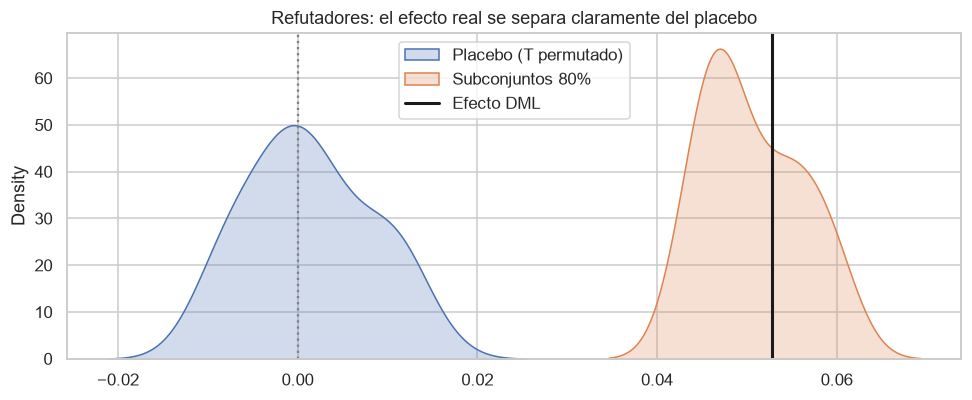

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.kdeplot(plac, fill=True, label="Placebo (T permutado)", ax=ax); sns.kdeplot(sub, fill=True, label="Subconjuntos 80%", ax=ax)
ax.axvline(theta, color="k", lw=2, label="Efecto DML"); ax.axvline(0, color="gray", ls=":")
ax.legend(); ax.set_title("Refutadores: el efecto real se separa claramente del placebo"); plt.tight_layout()
plt.savefig(FIG/"11_refutadores.png"); plt.show()

### 8.3 Sensibilidad a confusores no observados (acabados, piso, vista...)

No se puede probar que no existen, pero sí **medir cuán fuertes tendrían que ser** para anular el resultado:

- **Robustez de Cinelli-Hazlett (RV):** fuerza (en R² parcial con T *y* con Y) que debería tener un confusor omitido para reducir el efecto a 0 (o a la mitad).
- **E-value (VanderWeele-Ding):** riesgo relativo mínimo de asociación con T y Y para explicar el efecto.
- **Benchmark:** comparar con la fuerza de un confusor observado, p.ej. `area`.

In [24]:
from scipy import stats

# Cinelli-Hazlett sobre la regresión de residuos (DML ≈ FWL)
n, k = len(Y), X.shape[1]
t_stat = theta / se
dof = n - k - 2
f2 = t_stat**2 / dof                                     # R² parcial/(1-R²) de T̃ con Ỹ
rv0 = 0.5 * (np.sqrt(f2**2 + 4*f2) - f2)                 # RV_{q=1}: llevar el efecto a 0
q = 0.5; fq = q*np.sqrt(f2)
rv_half = 0.5 * (np.sqrt(fq**4 + 4*fq**2) - fq**2)       # RV_{q=0.5}: reducir el efecto a la mitad
print(f"Robustez RV (efecto→0): {100*rv0:.1f}% | RV (efecto→50%): {100*rv_half:.1f}%")
print("Un confusor omitido debería explicar ≥ %.1f%% de la varianza residual de T y de Y (ambas) para anular el efecto." % (100*rv0))

# E-value (Y continua: d = theta / sd(Y|X); RR ≈ exp(0.91 d))
sdy = np.std(ry)
d = abs(theta) / sdy
RR = np.exp(0.91*d); ev = RR + np.sqrt(RR*(RR-1))
d_lo = max(abs(theta) - 1.96*se, 0) / sdy; RR_lo = np.exp(0.91*d_lo); ev_lo = RR_lo + np.sqrt(RR_lo*(RR_lo-1)) if RR_lo > 1 else 1.0
print(f"E-value (punto): {ev:.2f} | E-value (límite IC95): {ev_lo:.2f}")

Robustez RV (efecto→0): 7.3% | RV (efecto→50%): 3.7%
Un confusor omitido debería explicar ≥ 7.3% de la varianza residual de T y de Y (ambas) para anular el efecto.
E-value (punto): 1.59 | E-value (límite IC95): 1.39


,R² parcial con T,R² parcial con Y,RV a vencer (T e Y)
area_log,0.1567,0.3355,0.0735
dormitorios,0.1735,0.0041,0.0735
antiguedad_imp,0.0303,0.0207,0.0735


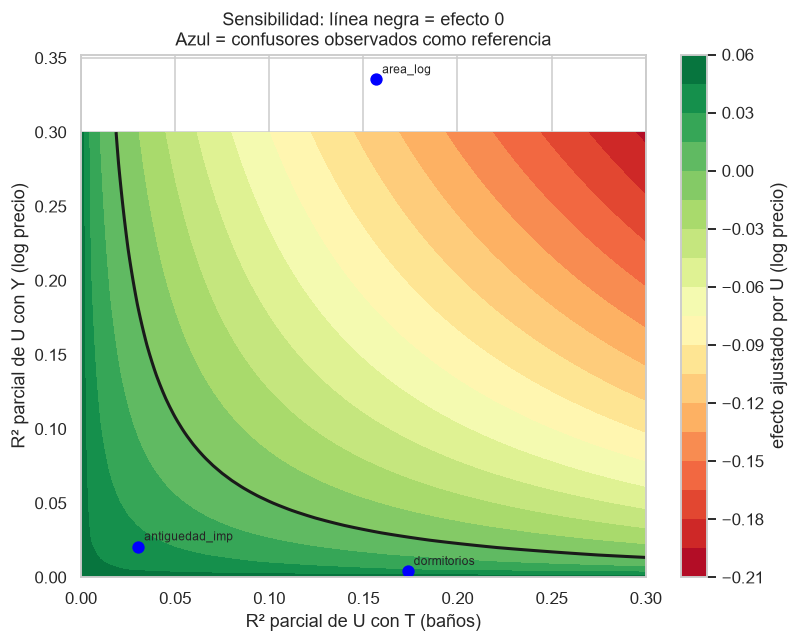

In [25]:
# Benchmark: ¿qué tan fuerte es un confusor OBSERVADO? (R² parcial de 'area_log' con T y con Y, dado el resto)
def r2_parcial(y, x, Z):
    Zc = sm.add_constant(Z)
    ry_ = sm.OLS(y, Zc).fit().resid; rx_ = sm.OLS(x, Zc).fit().resid
    return np.corrcoef(ry_, rx_)[0, 1]**2

resto = X.drop(columns=["area_log"])
bench = {v: (r2_parcial(T, X[v], X.drop(columns=[v])), r2_parcial(Y, X[v], X.drop(columns=[v]))) for v in ["area_log", "dormitorios", "antiguedad_imp"]}
bt = pd.DataFrame(bench, index=["R² parcial con T", "R² parcial con Y"]).T.round(4)
bt["RV a vencer (T e Y)"] = round(rv0, 4)
display(bt)

# Curva de contorno: efecto ajustado si U tuviera R²_T y R²_Y dados  (sesgo máx. = sqrt(R²y·R²t/(1-R²t)) · sd(Ỹ)/sd(T̃))
g = np.linspace(0, 0.3, 61); R2T, R2Y = np.meshgrid(g, g)
sesgo = np.sqrt(R2Y * R2T / (1 - R2T)) * np.std(ry) / np.std(rt)
ef_aj = theta - sesgo
fig, ax = plt.subplots(figsize=(7.5, 6))
cs = ax.contourf(R2T, R2Y, ef_aj, levels=20, cmap="RdYlGn"); plt.colorbar(cs, label="efecto ajustado por U (log precio)")
ax.contour(R2T, R2Y, ef_aj, levels=[0], colors="k", linewidths=2)
for v, (a, b) in bench.items(): ax.scatter(a, b, c="blue", s=50); ax.annotate(v, (a, b), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("R² parcial de U con T (baños)"); ax.set_ylabel("R² parcial de U con Y (log precio)")
ax.set_title("Sensibilidad: línea negra = efecto 0\nAzul = confusores observados como referencia"); plt.tight_layout()
plt.savefig(FIG/"12_sensibilidad_contorno.png"); plt.show()

**Cómo leerlo:** si un confusor omitido necesita ser *más fuerte que el área* (que ya está controlada) para anular el efecto, el resultado es razonablemente robusto; si basta con algo más débil, es frágil. Esta sección es la que sostiene (o no) la interpretación causal.

## 9. Resumen de resultados

In [26]:
resumen = pd.DataFrame({
    "método": ["Asociación bruta (OLS sin controles)", "OLS hedónico lineal", "DML manual (GBR, cross-fit)", "LinearDML (EconML)"],
    "efecto en log(precio)": [base.iloc[0]["efecto (log)"], base.iloc[2]["efecto (log)"], theta, ate_dml],
})
resumen["≈ % por baño extra"] = (100*(np.exp(resumen["efecto en log(precio)"])-1)).round(1)
display(resumen.round(4))
print(f"Precio medio: S/ {data['precio'].mean():.0f} → un baño extra ≈ S/ {data['precio'].mean()*(np.exp(ate_dml)-1):.0f} al mes (efecto medio, a igualdad de controles)")

,método,efecto en log(precio),≈ % por baño extra
0,Asociación bruta (OLS sin controles),0.3676,44.4
1,OLS hedónico lineal,0.0851,8.9
2,"DML manual (GBR, cross-fit)",0.0528,5.4
3,LinearDML (EconML),0.0528,5.4


Precio medio: S/ 3026 → un baño extra ≈ S/ 164 al mes (efecto medio, a igualdad de controles)


### Conclusiones y limitaciones

1. **Hallazgo central:** la asociación bruta entre baños y precio sobreestima el efecto causal porque los baños son un proxy de tamaño y zona; Double ML lo reduce a un efecto interpretable (ver tabla de resumen).
2. **Los controles se eligen con el DAG, no con "todo contra todos":** incluir `precioxm2` o `banos/dormitorio` distorsiona fuertemente la estimación (sección 5).
3. **Heterogeneidad:** los CATE por clase de distrito son similares (≈5.5–6.4%) y el IC del bosque causal es ancho (incluye 0 para el ATE); con ~3.3k observaciones **no hay evidencia sólida de heterogeneidad** relevante. Se reporta como exploratorio.
4. **Estructura aprendida:** PC recupera `área → baños → precio` y `área → precio` (coherente con el DAG), pero deja sin orientar `dormitorios — baños` y no detecta efecto de la ubicación sobre baños; LiNGAM da un efecto baños→precio positivo. Es consistencia parcial, no prueba (sin confusión oculta, flechas sin orientar).
5. **Limitación principal — confusores no observados:** acabados, piso, vista, amenities y seguridad no están en la base. El efecto pasa los refutadores (placebo ≈ 0, estable a subconjuntos), pero la sensibilidad es **moderada**: RV ≈ 7% y E-value ≈ 1.6 (1.4 en el límite del IC) → un confusor omitido de fuerza modesta (comparable a los observados, ver benchmark) podría reducirlo sustancialmente. Interpretar como efecto causal *condicional al DAG*, no como verdad. Mitigación futura: NLP sobre `descripcion` (piso, vista, remodelado, amoblado, cochera).
6. **Otras limitaciones:** `antiguedad` con 30% de faltantes (imputada + indicador); `dormitorios` es una variable dudosa (se reportan ambas especificaciones); datos de oferta (precio publicado, no transado); sólo 2 meses.
7. **Siguiente paso (Propuesta 3):** GeoRDD en fronteras entre distritos top y no-top para identificar el premio de ubicación con una estrategia distinta.